# 04 — Q1: frequência de interação × desempenho

**CRISP-DM, fases 4 e 5** · corresponde às seções **§6 e §7.1** de `docs/DOCUMENTACAO.md` e aos problemas 4 e 6 da §13

> **Q1 — Existe relação entre a frequência de interação do estudante com a plataforma e seu desempenho de aprendizagem?**

Neste notebook:
1. O método estatístico usado em todas as perguntas (§6)
2. ARES: Spearman, Pearson, **correlação parcial calculada passo a passo**, quartis
3. ARES: por que o notebook antigo dava **r = 0,118** e a documentação dá **ρ = 0,08**
4. EdNet: por que a acurácia precisa **excluir o diagnóstico** (ρ = 0,36 → 0,15)
5. Conclusão em quatro níveis e conferência com os resultados oficiais

In [5]:
import sys, json, warnings
from pathlib import Path

# encontra a raiz do projeto (pasta que contém src/config.py), venha o notebook de onde vier
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

import config as C
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Projeto:", ROOT)
from scipy import stats
from utils import spearman, partial_spearman, groups_test, quartiles, cliffs_delta, force

Projeto: C:\Users\Usuário\Desktop\Datasets-Beready\Datasets-Beready


## 1. Método (§6)

| Técnica | Para quê |
|---|---|
| **Spearman (ρ)** | Força e direção da relação **monotônica**, usando postos. Não supõe normalidade, é robusto a outliers e lida com empates |
| **IC 95% por bootstrap** | Faixa plausível do ρ, reamostrando os alunos 1.000 vezes, sem supor distribuição |
| **Spearman parcial** | Relação entre interação e desempenho **descontando o nível inicial** (pré-teste / diagnóstico). Evita confundir “quem já sabia mais” com “quem interagiu mais” |
| **Quartis + Kruskal-Wallis + Mann-Whitney + δ de Cliff** | Compara grupos do menos ao mais ativo, com tamanho de efeito |
| **Pearson (r)** | Só como sensibilidade (reproduz o notebook antigo) |

**Como ler o ρ:** |ρ| < 0,1 desprezível · 0,1–0,3 fraco · 0,3–0,5 moderado · ≥ 0,5 forte.

**Quatro níveis de leitura:** (1) o que foi **observado**; (2) se é **estatisticamente significativo** (p < 0,05); (3) se a **magnitude** tem relevância prática; (4) a **limitação causal**: é associação, não causa.

## 2. ARES

Base: os **141 alunos** com pré-teste, pós-teste e log de interação (notebook 02). Desempenho = **nota no pós-teste (0–11)**.

In [6]:
a = pd.read_csv(C.PROCESSED / "ares_alunos.csv")
perf = a[a["n_interacoes"] > 0].dropna(subset=["nota_pre", "nota_pos"]).copy()
print("Alunos na análise:", len(perf))
perf[["n_interacoes", "n_sessoes", "dias_ativos", "n_logins", "nota_pre", "nota_pos"]].describe().round(2)

Alunos na análise: 141


,n_interacoes,n_sessoes,dias_ativos,n_logins,nota_pre,nota_pos
count,141.00,141.00,141.00,141.00,141.00,141.00
mean,487.60,12.04,9.57,12.87,4.75,5.46
std,195.41,4.72,3.22,5.93,2.46,3.18
min,107.00,3.00,3.00,2.00,0.00,0.00
25%,363.00,9.00,8.00,9.00,3.00,3.00
50%,449.00,11.00,9.00,12.00,4.00,5.00
75%,583.00,14.00,11.00,16.00,6.00,8.00
max,1596.00,36.00,28.00,35.00,11.00,11.00


### 2.1 Por que Spearman e não Pearson?

Assimetria do nº de interações: 1.91  (0 = simétrico)
Shapiro-Wilk (normalidade) do nº de interações: p = 1.0e-09
Valores distintos da nota pós: 12 (notas discretas → muitos empates)


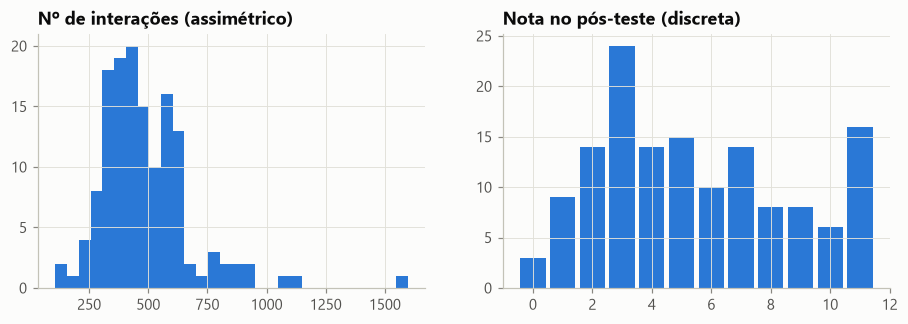

In [7]:
print(f"Assimetria do nº de interações: {stats.skew(perf['n_interacoes']):.2f}  (0 = simétrico)")
print(f"Shapiro-Wilk (normalidade) do nº de interações: p = {stats.shapiro(perf['n_interacoes']).pvalue:.1e}")
print(f"Valores distintos da nota pós: {perf['nota_pos'].nunique()} (notas discretas → muitos empates)")
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].hist(perf["n_interacoes"], bins=30, color="#2a78d6"); axs[0].set_title("Nº de interações (assimétrico)")
axs[1].hist(perf["nota_pos"], bins=np.arange(-0.5, 12), color="#2a78d6", rwidth=0.85); axs[1].set_title("Nota no pós-teste (discreta)")
plt.show()

➡️ A distribuição é muito assimétrica e não normal, com outliers, e a nota é discreta. **Spearman** é o adequado. Pearson fica só como sensibilidade.

### 2.2 Correlações

In [8]:
FREQ = {"n_interacoes": "Nº de interações", "n_sessoes": "Nº de sessões", "dias_ativos": "Dias ativos", "n_logins": "Nº de logins"}
linhas = []
for col, nome in FREQ.items():
    s = spearman(perf[col], perf["nota_pos"], boot=1000)          # ρ, p e IC95% por bootstrap
    r, pr = stats.pearsonr(perf[col], perf["nota_pos"])
    linhas.append({"métrica": nome, "Spearman ρ": s["rho"], "IC95%": s["ic95"], "p": round(s["p"], 3),
                   "Pearson r": round(r, 3), "p (Pearson)": round(pr, 3), "força": s["forca"]})
pd.DataFrame(linhas)

,métrica,Spearman ρ,IC95%,p,Pearson r,p (Pearson),força
0,Nº de interações,0.0789,"[-0.0856, 0.2397]",0.352,0.115,0.173,desprezível
1,Nº de sessões,0.0818,"[-0.0874, 0.2484]",0.335,0.043,0.611,desprezível
2,Dias ativos,0.0370,"[-0.1496, 0.2112]",0.663,-0.003,0.975,desprezível
3,Nº de logins,-0.0581,"[-0.2209, 0.1133]",0.493,-0.018,0.832,desprezível


### 2.3 Correlação parcial, passo a passo (controlando o pré-teste)

Pergunta: *entre alunos com o mesmo pré-teste, quem interage mais tira nota maior no pós?*

1. Transformar as três variáveis em **postos**
2. Regredir os postos de X (interações) e de Y (nota pós) nos postos do controle Z (nota pré)
3. Correlacionar os **resíduos**: a parte de X e de Y que o pré-teste não explica
4. Teste t com **n − 2 − k** graus de liberdade (k = 1 controle)

In [9]:
d = perf[["n_interacoes", "nota_pos", "nota_pre"]].rank()
Z = np.column_stack([np.ones(len(d)), d["nota_pre"]])
residuo = lambda y: y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
rx, ry = residuo(d["n_interacoes"].to_numpy()), residuo(d["nota_pos"].to_numpy())
rho_parcial = np.corrcoef(rx, ry)[0, 1]
gl = len(d) - 2 - 1
t = rho_parcial * np.sqrt(gl / (1 - rho_parcial ** 2))
p = 2 * stats.t.sf(abs(t), gl)
print(f"À mão:      ρ parcial = {rho_parcial:.4f} | t = {t:.3f} | gl = {gl} | p = {p:.3f}")
print("Função do projeto:", partial_spearman(perf["n_interacoes"], perf["nota_pos"], perf["nota_pre"]))

À mão:      ρ parcial = 0.0576 | t = 0.678 | gl = 138 | p = 0.499
Função do projeto: {'n': 141, 'rho_parcial': 0.0576, 'p': 0.4987623608159931, 'forca': 'desprezível'}


In [10]:
pd.DataFrame([{"métrica": n, **{k: v for k, v in partial_spearman(perf[c], perf["nota_pos"], perf["nota_pre"]).items() if k != "n"}}
              for c, n in FREQ.items()])

,métrica,rho_parcial,p,forca
0,Nº de interações,0.0576,0.498762,desprezível
1,Nº de sessões,0.0496,0.560831,desprezível
2,Dias ativos,0.0147,0.862863,desprezível
3,Nº de logins,-0.0038,0.964393,desprezível


### 2.4 Quartis de interação

In [11]:
perf["quartil_interacoes"] = quartiles(perf["n_interacoes"])
grupos = perf.groupby("quartil_interacoes", observed=True)["nota_pos"].agg(["count", "mean", "median"])
display(grupos.round(2))
g = groups_test(perf, "quartil_interacoes", "nota_pos")
print(f"Kruskal-Wallis entre os 4 quartis: H = {g['kruskal_H']}, p = {g['kruskal_p']:.3f}")
print(f"1º × 4º quartil (Mann-Whitney): p = {g['mannwhitney_p_alto_vs_baixo']:.2f} | δ de Cliff = {g['cliffs_delta_alto_vs_baixo']:+.2f}")

,count,mean,median
quartil_interacoes,,,
1º quartil (menos),36,5.86,6.0
2º quartil,35,4.09,3.0
3º quartil,35,5.74,4.0
4º quartil (mais),35,6.14,7.0


Kruskal-Wallis entre os 4 quartis: H = 9.03, p = 0.029
1º × 4º quartil (Mann-Whitney): p = 0.66 | δ de Cliff = +0.06


O Kruskal-Wallis dá p = 0,029, mas a diferença vem de uma **queda no 2º quartil** (média 4,1), **sem tendência**: o 1º e o 4º quartis são praticamente iguais (δ = 0,06).

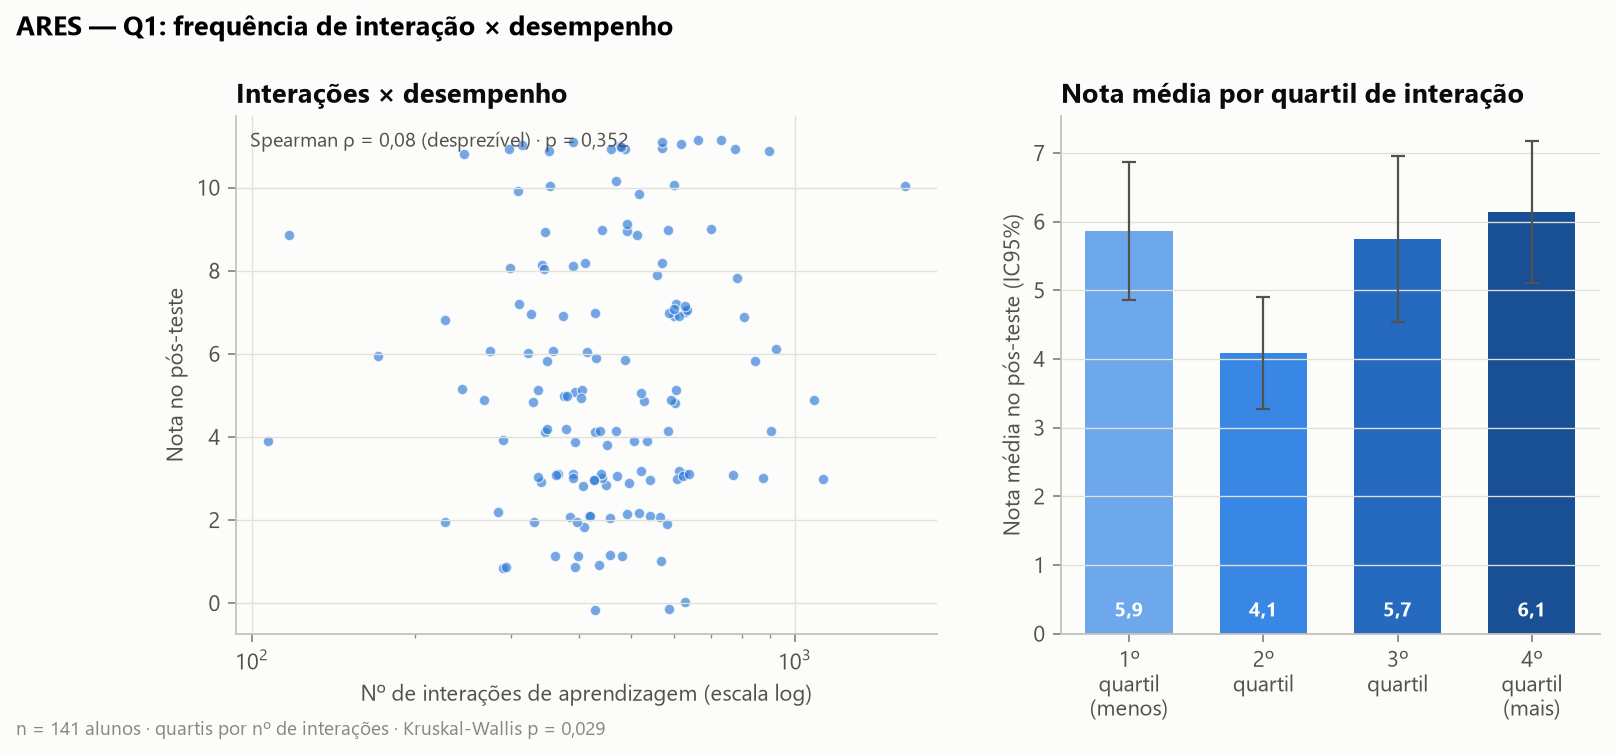

In [12]:
Image(filename=str(C.FIG / "ares" / "Q1_interacao_desempenho.png"))

## 3. Pearson 0,118 (notebook antigo) × Spearman 0,08 (documentação)

O `Test2_8y3zp.ipynb` (célula 41) calculou **Pearson** entre `num_interacoes` e `post_score` com critérios diferentes. Para medir o efeito de **cada** diferença, os critérios são aplicados um de cada vez, sempre com os mesmos 141 alunos:

| Cenário | Interações contadas | Nota |
|---|---|---|
| A — notebook antigo | todos os eventos, com as 2.184 duplicatas, provas, questionários e erros | soma das 12 questões (0–12) |
| B | igual a A | nota oficial 0–11 (sem Q9) |
| C | sem duplicatas | nota oficial |
| D — documentação | só eventos de aprendizagem (notebook 02) | nota oficial |

In [13]:
xapi = pd.read_excel(C.ARES_DIR / "preprocessed" / "xapi_statement_student.xlsx")
pos_resp = pd.read_excel(C.ARES_RAW / "post_test_response.xlsx").dropna(subset=["user_id"])
nota12 = pos_resp.assign(c=pos_resp["correct"].eq("t")).groupby("user_id")["c"].sum()      # como no notebook antigo
nota_oficial = pd.read_excel(C.ARES_RAW / "post_test_score.xlsx").set_index("user_id")["score"]
ids = perf["user_id"]
cenarios = {
    "A — notebook antigo": (xapi.groupby("actor").size(), nota12),
    "B — nota oficial": (xapi.groupby("actor").size(), nota_oficial),
    "C — sem duplicatas": (xapi.drop_duplicates().groupby("actor").size(), nota_oficial),
    "D — documentação": (perf.set_index("user_id")["n_interacoes"], nota_oficial),
}
linhas = []
for nome, (inter, nota) in cenarios.items():
    dd = pd.DataFrame({"i": inter.reindex(ids).values, "n": nota.reindex(ids).values}).dropna()
    r, pr = stats.pearsonr(dd["i"], dd["n"]); rho, ps = stats.spearmanr(dd["i"], dd["n"])
    linhas.append({"cenário": nome, "n": len(dd), "Pearson r": round(r, 3), "p (Pearson)": round(pr, 2),
                   "Spearman ρ": round(rho, 3), "p (Spearman)": round(ps, 2)})
pd.DataFrame(linhas)

,cenário,n,Pearson r,p (Pearson),Spearman ρ,p (Spearman)
0,A — notebook antigo,141,0.118,0.16,0.101,0.24
1,B — nota oficial,141,0.094,0.27,0.084,0.32
2,C — sem duplicatas,141,0.121,0.15,0.089,0.29
3,D — documentação,141,0.115,0.17,0.079,0.35


In [14]:
dd = perf[["n_interacoes", "nota_pos"]]
print(f"D com log das interações: Pearson r = {stats.pearsonr(np.log(dd['n_interacoes']), dd['nota_pos'])[0]:.3f}")
sem = perf[~perf["outlier_interacoes"]]
print(f"D sem os 4 outliers:       Pearson r = {stats.pearsonr(sem['n_interacoes'], sem['nota_pos'])[0]:.3f} | "
      f"Spearman ρ = {stats.spearmanr(sem['n_interacoes'], sem['nota_pos'])[0]:.3f}")
n_poder = int(np.ceil(((1.96 + 0.8416) / np.arctanh(0.118)) ** 2 + 3))
print(f"Alunos necessários para detectar r = 0,118 com 80% de poder: ~{n_poder}")

D com log das interações: Pearson r = 0.075
D sem os 4 outliers:       Pearson r = 0.100 | Spearman ρ = 0.072
Alunos necessários para detectar r = 0,118 com 80% de poder: ~562


**Leitura:**
- O **0,118 foi reproduzido exatamente** (cenário A). São os **mesmos 141 alunos**.
- A diferença para 0,08 vem **principalmente do método**: com os mesmos dados limpos (D), Pearson dá 0,115 e Spearman 0,079. A limpeza muda pouco.
- O Pearson fica mais alto porque alguns alunos com muitas interações puxam a reta. Com log das interações, ele cai para 0,075.
- **Em todos os cenários p > 0,15**: nenhum é significativo. A conclusão é a mesma com qualquer coeficiente.

➡️ **Spearman é o resultado principal; Pearson entra como análise de sensibilidade.**

## 4. EdNet

Desempenho = **acurácia nas questões fora do diagnóstico** (≥ 10). Base: 76.252 estudantes.

### 4.1 Por que excluir o diagnóstico?

O diagnóstico é um nivelamento **mais difícil** que a prática. Quem usa pouco o app quase só fez o diagnóstico; quem usa muito, quase só prática. A acurácia “geral” compara, portanto, provas diferentes conforme o volume de uso:

In [15]:
u = pd.read_csv(C.PROCESSED / "ednet_users.csv.gz")
geral = u[u["n_respondidas"] >= C.EDNET_MIN_ANSWERS].copy()
geral["pct_diagnostico"] = geral["resp_diagnosis"] / geral["n_respondidas"]
geral["quartil"] = quartiles(geral["n_eventos"])
print(f"Acurácia no diagnóstico: {u['acerto_diagnosis'].sum() / u['resp_diagnosis'].sum():.1%} | "
      f"na prática (sprint): {u['acerto_sprint'].sum() / u['resp_sprint'].sum():.1%}")
display(geral.groupby("quartil", observed=True).agg(
    mediana_pct_respostas_no_diagnostico=("pct_diagnostico", "median"), acuracia_geral_media=("acuracia", "mean")).round(3))
print(f"ρ(interações, % de diagnóstico) = {stats.spearmanr(geral['n_eventos'], geral['pct_diagnostico'])[0]:.2f}")
print(f"ρ(interações, acurácia GERAL)   = {stats.spearmanr(geral['n_eventos'], geral['acuracia'])[0]:.2f}  ← versão anterior (inflada)")

Acurácia no diagnóstico: 47.4% | na prática (sprint): 66.4%


,mediana_pct_respostas_no_diagnostico,acuracia_geral_media
quartil,,
1º quartil (menos),1.000,0.515
2º quartil,0.500,0.529
3º quartil,0.200,0.599
4º quartil (mais),0.028,0.651


ρ(interações, % de diagnóstico) = -0.93
ρ(interações, acurácia GERAL)   = 0.36  ← versão anterior (inflada)


➡️ No 1º quartil, a mediana é de **100%** das respostas no diagnóstico; no 4º, **3%**. Parte do 0,36 era só **o tipo de questão**. Corrigindo:

### 4.2 Correlações com a acurácia fora do diagnóstico

In [16]:
nd = u["n_respondidas"] - u["resp_diagnosis"]
u["acuracia_pos_diag"] = np.where(nd >= C.EDNET_MIN_ANSWERS, (u["n_acertos"] - u["acerto_diagnosis"]) / nd.clip(lower=1), np.nan)
u["acuracia_diag"] = np.where(u["resp_diagnosis"] >= 5, u["acerto_diagnosis"] / u["resp_diagnosis"], np.nan)
p_ed = u.dropna(subset=["acuracia_pos_diag"]).copy()
ctrl = u.dropna(subset=["acuracia_diag", "acuracia_pos_diag"])
print("Estudantes:", len(p_ed), "| com diagnóstico (para o controle):", len(ctrl))
linhas = []
for col, nome in {"n_eventos": "Nº de interações", "n_sessoes": "Nº de sessões", "dias_ativos": "Dias ativos"}.items():
    s = spearman(p_ed[col], p_ed["acuracia_pos_diag"], boot=200)
    pc = partial_spearman(ctrl[col], ctrl["acuracia_pos_diag"], ctrl["acuracia_diag"])
    linhas.append({"métrica": nome, "ρ": s["rho"], "IC95%": s["ic95"], "p": f"{s['p']:.1e}", "força": s["forca"],
                   "ρ parcial (controle do diagnóstico)": pc["rho_parcial"]})
pd.DataFrame(linhas)

Estudantes: 76252 | com diagnóstico (para o controle): 66062


,métrica,ρ,IC95%,p,força,ρ parcial (controle do diagnóstico)
0,Nº de interações,0.1491,"[0.1359, 0.1636]",0.0e+00,fraca,0.1410
1,Nº de sessões,0.0826,"[0.0687, 0.0972]",1.5e-115,desprezível,0.0768
2,Dias ativos,0.0701,"[0.057, 0.0844]",1.4e-83,desprezível,0.0665


In [17]:
p_ed["quartil"] = quartiles(p_ed["n_eventos"])
gq = p_ed.groupby("quartil", observed=True)["acuracia_pos_diag"].mean()
display((gq * 100).round(1).rename("acurácia média (%)").to_frame())
g = groups_test(p_ed, "quartil", "acuracia_pos_diag")
print(f"δ de Cliff (4º × 1º quartil) = {g['cliffs_delta_alto_vs_baixo']:.2f} → efeito pequeno "
      f"(|δ| < 0,15 desprezível · < 0,33 pequeno · < 0,47 médio · ≥ 0,47 grande)")
print(f"Diferença entre o 4º e o 1º quartil: {(gq.iloc[-1] - gq.iloc[0]) * 100:.1f} p.p.")

,acurácia média (%)
quartil,
1º quartil (menos),60.3
2º quartil,62.4
3º quartil,64.2
4º quartil (mais),66.4


δ de Cliff (4º × 1º quartil) = 0.21 → efeito pequeno (|δ| < 0,15 desprezível · < 0,33 pequeno · < 0,47 médio · ≥ 0,47 grande)
Diferença entre o 4º e o 1º quartil: 6.1 p.p.


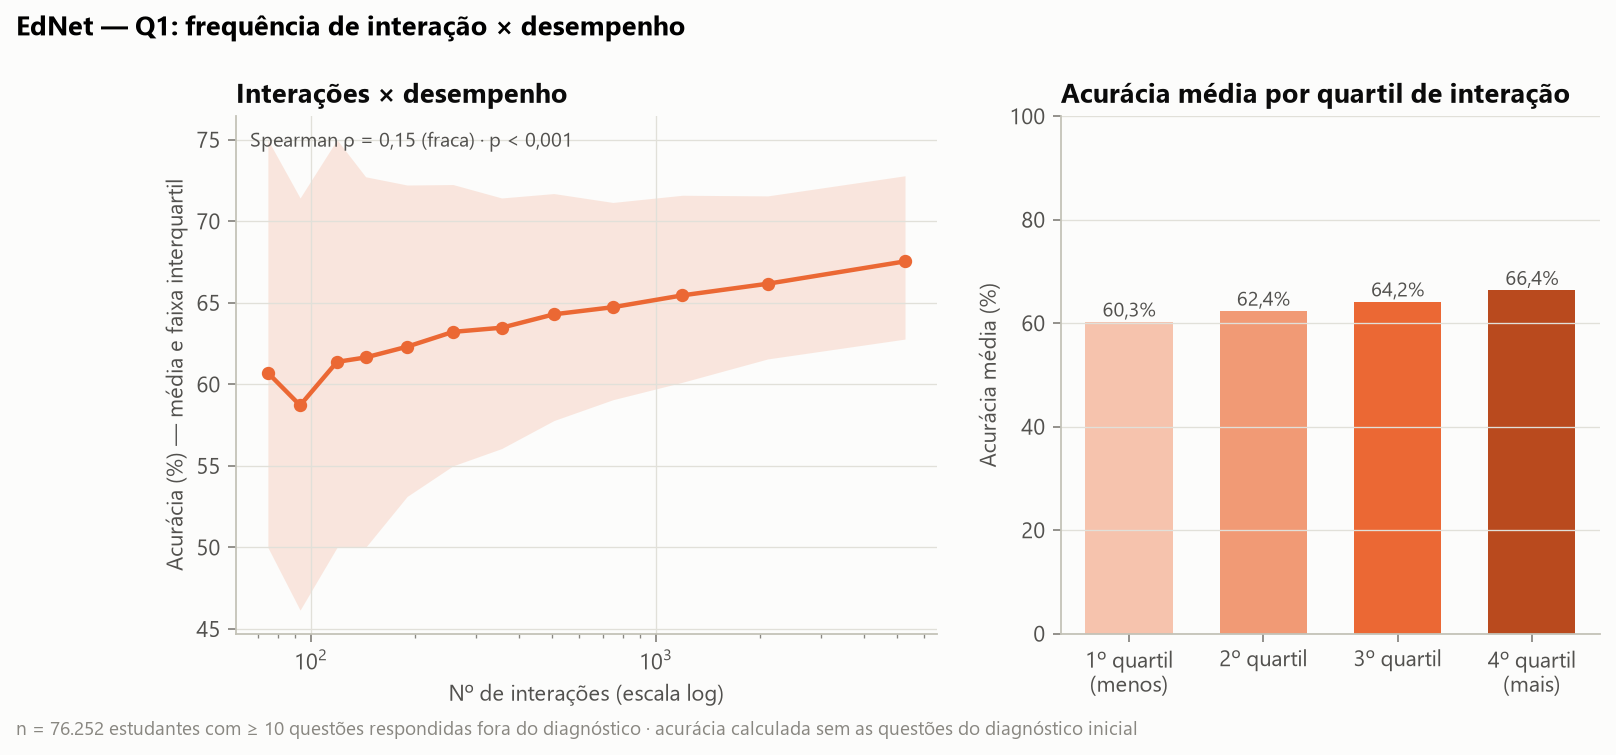

In [18]:
Image(filename=str(C.FIG / "ednet" / "Q1_interacao_desempenho.png"))

## 5. Conclusão da Q1

| | ARES (n = 141) | EdNet (n = 76.252) |
|---|---|---|
| **Observado** | ρ = +0,08 (Pearson +0,12) entre interações e nota pós | ρ = +0,15 entre interações e acurácia fora do diagnóstico; +0,14 descontando o diagnóstico |
| **Significância** | Não significativo (p = 0,35) | Significativo (p < 0,001), por causa do tamanho da base |
| **Magnitude** | Desprezível; IC95% (−0,09 a +0,24) não descarta efeito fraco | **Fraca**; 4º quartil acerta ~6 p.p. a mais que o 1º; sessões e dias: desprezíveis |
| **Causa?** | — | Não: estudantes mais motivados ou com mais tempo podem tanto usar mais quanto acertar mais |

**Resposta:** a associação entre frequência de interação e desempenho é **fraca (EdNet) ou não detectada (ARES)**. A quantidade de interação, sozinha, prevê pouco do desempenho.

In [19]:
R_A = json.loads((C.TAB / "ares_resultados.json").read_text(encoding="utf-8"))
R_E = json.loads((C.TAB / "ednet_resultados.json").read_text(encoding="utf-8"))
conf = {
    "ARES ρ": (R_A["Q1"]["correlacoes"]["n_interacoes"]["rho"], stats.spearmanr(perf["n_interacoes"], perf["nota_pos"])[0]),
    "ARES ρ parcial": (R_A["Q1"]["parciais_controle_pre"]["n_interacoes"]["rho_parcial"], rho_parcial),
    "EdNet n": (R_E["Q1"]["populacao"], len(p_ed)),
    "EdNet ρ": (R_E["Q1"]["correlacoes"]["n_eventos"]["rho"], stats.spearmanr(p_ed["n_eventos"], p_ed["acuracia_pos_diag"])[0]),
    "EdNet ρ parcial": (R_E["Q1"]["parciais_controle_diagnostico"]["n_eventos"]["rho_parcial"],
                        partial_spearman(ctrl["n_eventos"], ctrl["acuracia_pos_diag"], ctrl["acuracia_diag"])["rho_parcial"]),
}
tab = pd.DataFrame(conf, index=["oficial (outputs/tables)", "este notebook"]).T
tab["confere"] = np.isclose(tab.iloc[:, 0].astype(float), tab.iloc[:, 1].astype(float), atol=1e-3)
display(tab)
assert tab["confere"].all()
print("✅ Os números deste notebook são os mesmos da documentação e dos resultados oficiais.")

,oficial (outputs/tables),este notebook,confere
ARES ρ,0.0789,0.078900,True
ARES ρ parcial,0.0576,0.057639,True
EdNet n,76252.0000,76252.000000,True
EdNet ρ,0.1491,0.149108,True
EdNet ρ parcial,0.1410,0.141000,True


✅ Os números deste notebook são os mesmos da documentação e dos resultados oficiais.


**Próximo:** `05_Q4_engajamento.ipynb`.